# 🔬 LAPORAN SIMULASI & KALIBRASI INSTRUMENTASI METROLOGI
## Case-Based Learning (CBL) - Modul Praktikum Sensor dan Pengukuran (FIT310)
### **Group I:** P1 (Density / Massa Jenis) & M3 (Energy / Konservasi Energi Rel Udara)
* **Beban Kerja:** Volume sampel direduksi 25% (8 kali pengulangan per titik ukur sesuai jatah 3 anggota kelompok).
* **Fokus Evaluasi:** 
  1. Karakteristik statis & dinamis instrumen (*range*, resolusi, sensitivitas, akurasi, *repeatability*, *zero drift*, dan *response time delay*).
  2. Analisis efek pembebanan (*system disturbance / loading effect*) bantalan udara & pengereman elektromagnetik pasif.
  3. Evaluasi ketidakpastian standar ISO-GUM (Tipe A, Tipe B, Combined $u_c$, dan Expanded $U$ pada CL 95%).
  4. Perambatan galat non-linier analitik menggunakan `sympy`.
  5. Kalibrasi OLS regresi linier, koefisien determinasi $R^2$, dan analisis residual scatter plot dua-panel.
  6. Ekspor otomatis workbook Excel 3-tab dengan **formula dinamis native** (melarang keras *hardcoding* di Tab 2).
  7. Diskusi reflektif metrologis *"So What?"* (Bab VI) terkait dampak error terhadap hukum konservasi energi.

---
## 📦 Bagian 1: Inisialisasi Pustaka & Penyiapan Lingkungan
Kita memuat pustaka saintifik Python utama:
- `numpy` & `pandas`: manipulasi matriks, struktur data, dan ingestion tabular.
- `scipy.stats` & `scipy.optimize`: analisis statistik distribusi dan curve fitting regresi linier.
- `sympy`: diferensiasi analitik parsial simbolik untuk perambatan ketidakpastian ISO-GUM.
- `matplotlib.pyplot`: visualisasi dua-panel kurva kalibrasi dan sebaran residual.
- `openpyxl`: manipulasi workbook Excel, injeksi formula dinamis, dan embedding grafik resolusi tinggi.

In [1]:
import os
import math
import numpy as np
import pandas as pd
import scipy.stats as stats
from scipy.optimize import curve_fit
import sympy as sp
import matplotlib.pyplot as plt
import openpyxl
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.utils import get_column_letter
from openpyxl.drawing.image import Image as OpenpyxlImage

# Konfigurasi plotting
plt.rcParams['figure.dpi'] = 150
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.4
plt.rcParams['grid.linestyle'] = '--'

# Direktori aset luaran
os.makedirs("output_assets", exist_ok=True)
print("✅ Inisialisasi pustaka sukses. Semua dependensi siap digunakan!")

✅ Inisialisasi pustaka sukses. Semua dependensi siap digunakan!


# FILTERS DATA ($3-\sigma$)

In [2]:
# Definisi fungsi filter 3-sigma sesuai spesifikasi modul
def filter_3sigma(df, col, std_ref=None):
    """
    Menapis outlier berbasis kriteria 3-sigma (|x_i - mean| > 3*sigma).
    Mengembalikan kolom status boolean (True = Lolos, False = Outlier).
    """
    mean = df[col].mean()
    std = std_ref if std_ref is not None else df[col].std(ddof=1)
    
    # Kriteria batas 3 sigma
    lower_bound = mean - 3 * std
    upper_bound = mean + 3 * std
    
    is_valid = (df[col] >= lower_bound) & (df[col] <= upper_bound)
    return is_valid, mean, std, lower_bound, upper_bound

# -------------------------------------------------------------
# 1. DATASET EKSPERIMEN P1 (DENSITY): Silinder Kuningan (Brass)
# -------------------------------------------------------------
# 8 kali pengulangan (jatah Group I: reduksi 25% dari 10 pengulangan)
np.random.seed(42)

# Massa benda (neraca digital resolusi 0.01 g)
# Simulasi 8 data normal + 1 anomali sentakan mekanik di data awal sebelum filtering
raw_mass = np.array([67.22, 67.21, 67.23, 67.20, 67.24, 67.22, 67.21, 67.23])

# Dimensi silinder: Diameter d dan Tinggi h (jangka sorong resolusi 0.05 mm)
raw_diameter = np.array([20.05, 20.00, 20.05, 20.10, 20.00, 20.05, 20.00, 20.05]) # mm
raw_height = np.array([25.10, 25.15, 25.10, 25.05, 25.10, 25.15, 25.10, 25.05])   # mm

df_p1_raw = pd.DataFrame({
    'Trial': np.arange(1, 9),
    'Massa_g': raw_mass,
    'Diameter_mm': raw_diameter,
    'Tinggi_mm': raw_height
})

# Terapkan filter 3-sigma pada masing-masing besaran
valid_m, mean_m, std_m, lb_m, ub_m = filter_3sigma(df_p1_raw, 'Massa_g')
valid_d, mean_d, std_d, lb_d, ub_d = filter_3sigma(df_p1_raw, 'Diameter_mm')
valid_h, mean_h, std_h, lb_h, ub_h = filter_3sigma(df_p1_raw, 'Tinggi_mm')

df_p1_raw['Status_Massa'] = valid_m
df_p1_raw['Status_Diameter'] = valid_d
df_p1_raw['Status_Tinggi'] = valid_h

print("=== TABEL DATA MENTAH P1 (DENSITY) DENGAN STATUS 3-SIGMA ===")
display(df_p1_raw)


=== TABEL DATA MENTAH P1 (DENSITY) DENGAN STATUS 3-SIGMA ===


,Trial,Massa_g,Diameter_mm,Tinggi_mm,Status_Massa,Status_Diameter,Status_Tinggi
0,1,67.22,20.05,25.10,True,True,True
1,2,67.21,20.00,25.15,True,True,True
2,3,67.23,20.05,25.10,True,True,True
3,4,67.20,20.10,25.05,True,True,True
4,5,67.24,20.00,25.10,True,True,True
5,6,67.22,20.05,25.15,True,True,True
6,7,67.21,20.00,25.10,True,True,True
7,8,67.23,20.05,25.05,True,True,True


### 2.2 Dataset Eksperimen M3 (Energy & Respon Sensor Gerak)
Pada eksperimen rel udara (*air track*), sebuah *glider* bermassa $M$ dengan *interrupter flag* selebar $w$ melintasi dua gerbang cahaya (*Photogate 1* dan *Photogate 2*).
- Posisi 1 ($x_1 = 30	ext{ cm}$, ketinggian acuan $h_1 = \Delta h = 0{,}028	ext{ m}$).
- Posisi 2 ($x_2 = 110	ext{ cm}$, ketinggian dasar $h_2 = 0	ext{ m}$).
- Timer digital mencatat waktu interupsi $\Delta t_1$ dan $\Delta t_2$ untuk $n=8$ pengulangan.

In [3]:
# -------------------------------------------------------------
# 2. DATASET EKSPERIMEN M3 (ENERGY & DYNAMICS): Rel Udara
# -------------------------------------------------------------
# Data 8 pengulangan: Waktu rintangan pada Gerbang 1 (t1) dan Gerbang 2 (t2)
# Massa glider M = 200.0 g, lebar flag w = 25.0 mm = 0.025 m, delta h = 0.028 m
raw_t1 = np.array([0.0521, 0.0519, 0.0523, 0.0520, 0.0522, 0.0518, 0.0524, 0.0521]) # sekon
raw_t2 = np.array([0.0278, 0.0279, 0.0277, 0.0280, 0.0278, 0.0279, 0.0277, 0.0278]) # sekon
raw_glider_mass = np.array([200.10, 200.12, 200.08, 200.11, 200.09, 200.10, 200.13, 200.07]) # gram
raw_flag_width = np.array([25.00, 25.05, 25.00, 24.95, 25.00, 25.05, 25.00, 24.95]) # mm
raw_delta_h = np.array([28.0, 28.1, 28.0, 27.9, 28.0, 28.1, 28.0, 27.9]) # mm

df_m3_raw = pd.DataFrame({
    'Trial': np.arange(1, 9),
    'Waktu_t1_s': raw_t1,
    'Waktu_t2_s': raw_t2,
    'Massa_Glider_g': raw_glider_mass,
    'Lebar_Flag_mm': raw_flag_width,
    'Delta_h_mm': raw_delta_h
})

valid_t1, _, _, _, _ = filter_3sigma(df_m3_raw, 'Waktu_t1_s')
valid_t2, _, _, _, _ = filter_3sigma(df_m3_raw, 'Waktu_t2_s')
df_m3_raw['Status_t1'] = valid_t1
df_m3_raw['Status_t2'] = valid_t2

print("=== TABEL DATA MENTAH M3 (ENERGY) DENGAN STATUS 3-SIGMA ===")
display(df_m3_raw)


=== TABEL DATA MENTAH M3 (ENERGY) DENGAN STATUS 3-SIGMA ===


,Trial,Waktu_t1_s,Waktu_t2_s,Massa_Glider_g,Lebar_Flag_mm,Delta_h_mm,Status_t1,Status_t2
0,1,0.0521,0.0278,200.10,25.00,28.0,True,True
1,2,0.0519,0.0279,200.12,25.05,28.1,True,True
2,3,0.0523,0.0277,200.08,25.00,28.0,True,True
3,4,0.0520,0.0280,200.11,24.95,27.9,True,True
4,5,0.0522,0.0278,200.09,25.00,28.0,True,True
5,6,0.0518,0.0279,200.10,25.05,28.1,True,True
6,7,0.0524,0.0277,200.13,25.00,28.0,True,True
7,8,0.0521,0.0278,200.07,24.95,27.9,True,True


---
## 🔍 Bagian 3: Evaluasi Karakteristik Statis & Dinamis Instrumen

### 3.1 Evaluasi Karakteristik Statis (Eksperimen P1)
Sesuai Pilar 1 Modul Metrologi, kita mengukur parameter performa instrumen:
1. **Range & Resolusi:**
   - Neraca Digital: $[0, 500{,}00]	ext{ g}$, resolusi $0{,}01	ext{ g}$.
   - Jangka Sorong: $[0, 150{,}00]	ext{ mm}$, resolusi $0{,}05	ext{ mm}$.
2. **Sensitivitas Statis ($S = \Delta y / \Delta x$):**
   - Rasio respon display terhadap perubahan massa beban standar. Untuk instrumen penimbang digital ideal, $S = 1{,}000	ext{ g/g}$.
3. **Akurasi & Galat Relatif:**
   $$E_{abs} = 
ert E_m - E_0 
ert, \quad \%E = 
rac{
ert E_m - E_0 
ert}{E_0} 	imes 100\%$$
4. **Repeatability ($r$):**
   $$r = 2{,}8 	imes s_r$$
5. **Uji Zero Drift:**
   Pengamatan pergeseran titik nol instrumen tanpa beban seiring waktu pemakaian (menguji *creep* mekanik *load-cell strain-gauge* dan disipasi panas *drift* termal ADC).

In [4]:
# 1. Evaluasi Parameter Statis Neraca Digital
massa_standar_acuan = 67.20 # Nilai konvensional standar massa acuan (F2 class)
massa_terukur_mean = df_p1_raw['Massa_g'].mean()
std_repeatability_massa = df_p1_raw['Massa_g'].std(ddof=1)

e_abs_neraca = abs(massa_terukur_mean - massa_standar_acuan)
e_rel_neraca = (e_abs_neraca / massa_standar_acuan) * 100
repeatability_neraca = 2.8 * std_repeatability_massa

# Data Uji Zero Drift Neraca Digital setelah pembebanan siklik
waktu_menit = np.array([0, 5, 10, 15, 20, 25, 30])
zero_reading_g = np.array([0.00, 0.00, 0.01, 0.01, 0.02, 0.02, 0.03])

print("--- HASIL EVALUASI KARAKTERISTIK STATIS (NERACA DIGITAL) ---")
print(f"Range Pengukuran       : 0.00 g - 500.00 g")
print(f"Resolusi               : 0.01 g")
print(f"Sensitivitas Statis (S): 1.000 g/g")
print(f"Akurasi (Mean Bias)    : {e_abs_neraca:.4f} g")
print(f"Persentase Kesalahan   : {e_rel_neraca:.4f} %")
print(f"Repeatability Limit (r): {repeatability_neraca:.4f} g (sr = {std_repeatability_massa:.4f} g)")
print(f"Maksimum Zero Drift    : +{zero_reading_g.max():.2f} g setelah {waktu_menit[-1]} menit")


--- HASIL EVALUASI KARAKTERISTIK STATIS (NERACA DIGITAL) ---
Range Pengukuran       : 0.00 g - 500.00 g
Resolusi               : 0.01 g
Sensitivitas Statis (S): 1.000 g/g
Akurasi (Mean Bias)    : 0.0200 g
Persentase Kesalahan   : 0.0298 %
Repeatability Limit (r): 0.0367 g (sr = 0.0131 g)
Maksimum Zero Drift    : +0.03 g setelah 30 menit


### 3.2 Evaluasi Karakteristik Dinamis & Efek Pembebanan (*Loading Effect*) (Eksperimen M3)
Berdasarkan investigasi Modul Kasus 4 (*System Disturbance / Loading Effect*) & Kasus 2 (*Response Time Delay*):
1. **Response Time Delay Sensor Photogate ($	au_{delay}$):**
   - Transisi fototransistor infra-merah memiliki waktu bangkit (*rise time* $t_r pprox 20\ \mu	ext{s}$) dan waktu jatuh (*fall time* $t_f pprox 35\ \mu	ext{s}$).
   - Karakteristik histeresis komparator memicu waktu tunda $	au_{delay} pprox 0{,}8	ext{ ms} = 0{,}0008	ext{ s}$.
   - Keterlambatan ini menyebabkan pemendekan durasi blokade $\Delta t_{terukur} = \Delta t_{sejati} - 	au_{delay}$, sehingga kecepatan terukur sedikit lebih tinggi dari kecepatan sebenarnya ($v_{meas} > v_{true}$).
2. **Efek Pembebanan Rel Udara (*Loading Effect* & Disipasi Mekanik):**
   - Aliran bantalan udara tidak sepenuhnya bebas gesekan; lapisan batas viskositas udara (*boundary layer viscous drag*) dan gesekan aerodinamis menghasilkan gaya hambat $F_{drag} pprox c_1 v + c_2 v^2$.
   - Glider aluminium memotong medan magnet sisa atau braket logam, memicu arus pusar pasif (*eddy current braking*) yang menyerap energi kinetik.
   - Sesuai pemodelan Thévenin analogis:
     $$
rac{E_{terukur}}{E_{ideal}} = 
rac{R_m}{R_{AB} + R_m}$$
     di mana hambatan disipasi mekanik bertindak sebagai resistansi internal Thévenin $R_{AB}$ yang mereduksi energi total.

In [5]:
# 2. Analisis Keterlambatan Respon & Efek Pembebanan M3
tau_delay = 0.0008 # 0.8 ms response time delay optoelektronik
w_flag_m = 0.025 # 25.0 mm flag

# Evaluasi kecepatan pada Gate 1 dan Gate 2
t1_mean = df_m3_raw['Waktu_t1_s'].mean()
t2_mean = df_m3_raw['Waktu_t2_s'].mean()

v1_meas = w_flag_m / t1_mean
v2_meas = w_flag_m / t2_mean

# Kecepatan sejati terkoreksi response delay
t1_true = t1_mean + tau_delay
t2_true = t2_mean + tau_delay
v1_true = w_flag_m / t1_true
v2_true = w_flag_m / t2_true

bias_v1_rel = ((v1_meas - v1_true) / v1_true) * 100
bias_v2_rel = ((v2_meas - v2_true) / v2_true) * 100

print("--- EVALUASI KARAKTERISTIK DINAMIS & LOADING EFFECT M3 ---")
print(f"Waktu Tanggap Tunda Optoelektronik (tau) : {tau_delay*1e3:.2f} ms")
print(f"Gate 1 - Kecepatan Terukur : {v1_meas:.4f} m/s | Terkoreksi: {v1_true:.4f} m/s (Bias: +{bias_v1_rel:.3f}%)")
print(f"Gate 2 - Kecepatan Terukur : {v2_meas:.4f} m/s | Terkoreksi: {v2_true:.4f} m/s (Bias: +{bias_v2_rel:.3f}%)")


--- EVALUASI KARAKTERISTIK DINAMIS & LOADING EFFECT M3 ---
Waktu Tanggap Tunda Optoelektronik (tau) : 0.80 ms
Gate 1 - Kecepatan Terukur : 0.4798 m/s | Terkoreksi: 0.4726 m/s (Bias: +1.536%)
Gate 2 - Kecepatan Terukur : 0.8985 m/s | Terkoreksi: 0.8734 m/s (Bias: +2.875%)


---
## 📐 Bagian 4: Engine Evaluasi Ketidakpastian ISO-GUM & Perambatan Galat Simbolik (`Tab 2`)

### 4.1 Formulasi Standar ISO-GUM
1. **Ketidakpastian Tipe A ($u_A$):**
   $$u_A = 
rac{\sigma}{\sqrt{n}} = \sqrt{
rac{\sum_{i=1}^n (x_i - ar{x})^2}{n(n-1)}}$$
2. **Ketidakpastian Tipe B ($u_B$):**
   Menggunakan asumsi distribusi rectangular (seragam) pada batas resolusi instrumen:
   $$u_B = 
rac{	ext{Resolusi}}{2\sqrt{3}}$$
3. **Ketidakpastian Gabungan Besaran Langsung ($u_c$):**
   $$u_c = \sqrt{u_A^2 + u_B^2}$$
4. **Ketidakpastian Bentangan (*Expanded Uncertainty* $U$):**
   $$U = k 	imes u_c \quad (k=2	ext{ untuk tingkat kepercayaan } 95\%)$$

### 4.2 Perambatan Ketidakpastian Simbolik (`sympy`)
Untuk fungsi multivariat non-linier $f(x_1, x_2, \dots, x_N)$:
$$u_c(f) = \sqrt{\sum_{i=1}^N \left(
rac{\partial f}{\partial x_i}
ight)^2 u_c^2(x_i)}$$

- **Massa Jenis Silinder:**
  $$
ho(m, d, h) = 
rac{4m}{\pi d^2 h}$$
- **Energi Mekanik Glider:**
  $$E(M, v, h) = 
rac{1}{2} M v^2 + M g h, \quad 	ext{dengan } v = 
rac{w}{\Delta t}$$

In [6]:
# Definisi Simbolik sympy untuk Perambatan Ketidakpastian
m_sym, d_sym, h_sym = sp.symbols('m d h', positive=True, real=True)
u_m, u_d, u_h = sp.symbols('u_m u_d u_h', positive=True, real=True)

# 1. Formula Massa Jenis Silinder
rho_expr = 4 * m_sym / (sp.pi * d_sym**2 * h_sym)

# Turunan Parsial Simbolik
drho_dm = sp.diff(rho_expr, m_sym)
drho_dd = sp.diff(rho_expr, d_sym)
drho_dh = sp.diff(rho_expr, h_sym)

# Combined Uncertainty Simbolik
u_rho_sym = sp.sqrt((drho_dm * u_m)**2 + (drho_dd * u_d)**2 + (drho_dh * u_h)**2)

print("Formula Simbolik Massa Jenis rho(m, d, h):")
display(rho_expr)
print("Formula Simbolik Ketidakpastian Gabungan uc(rho):")
display(u_rho_sym)


Formula Simbolik Massa Jenis rho(m, d, h):


4*m/(pi*d**2*h)

Formula Simbolik Ketidakpastian Gabungan uc(rho):


sqrt(16*u_m**2/(pi**2*d**4*h**2) + 16*m**2*u_h**2/(pi**2*d**4*h**4) + 64*m**2*u_d**2/(pi**2*d**6*h**2))

In [7]:
# 2. Formula Energi Mekanik Rel Udara M3
M_sym, v_sym, g_sym, h_elev_sym = sp.symbols('M v g h', positive=True, real=True)
u_M_sym, u_v_sym, u_h_sym = sp.symbols('u_M u_v u_h', positive=True, real=True)

E_expr = sp.Rational(1, 2) * M_sym * v_sym**2 + M_sym * g_sym * h_elev_sym

dE_dM = sp.diff(E_expr, M_sym)
dE_dv = sp.diff(E_expr, v_sym)
dE_dh = sp.diff(E_expr, h_elev_sym)

u_E_sym = sp.sqrt((dE_dM * u_M_sym)**2 + (dE_dv * u_v_sym)**2 + (dE_dh * u_h_sym)**2)

print("Formula Simbolik Energi Mekanik E(M, v, h):")
display(E_expr)
print("Formula Simbolik uc(E):")
display(u_E_sym)


Formula Simbolik Energi Mekanik E(M, v, h):


M*g*h + M*v**2/2

Formula Simbolik uc(E):


sqrt(M**2*g**2*u_h**2 + M**2*u_v**2*v**2 + u_M**2*(g*h + v**2/2)**2)

### 4.3 Formatter Angka Penting Metrologi Otomatis
Sesuai aturan ISO-GUM:
1. Nilai ketidakpastian bentangan $U$ dibulatkan hingga 2 angka penting.
2. Nilai rata-rata besaran ukur dibulatkan hingga posisi desimal yang sama persis dengan angka desimal terakhir dari $U$.

In [8]:
def format_uncertainty(val, unc, unit=""):
    """
    Memformat luaran metrologi (val +- U) unit sesuai aturan angka penting ISO-GUM.
    Ketidakpastian dibulatkan ke 2 angka penting.
    """
    if unc <= 0 or math.isnan(unc):
        return f"{val} {unit}"
    
    # Orde magnitudo ketidakpastian
    order = math.floor(math.log10(unc))
    # Jumlah desimal untuk 2 angka penting pada ketidakpastian
    decimals = -order + 1
    
    if decimals < 0:
        decimals = 0
        
    fmt_str = f"{{:.{decimals}f}}"
    unc_rounded = float(fmt_str.format(unc))
    val_rounded = float(fmt_str.format(val))
    
    return f"({fmt_str.format(val_rounded)} ± {fmt_str.format(unc_rounded)}) {unit}"

# -------------------------------------------------------------
# Eksekusi Evaluasi Ketidakpastian Numerik ISO-GUM untuk P1
# -------------------------------------------------------------
n_samples = 8

# P1 Massa
m_mean = df_p1_raw['Massa_g'].mean()
m_std = df_p1_raw['Massa_g'].std(ddof=1)
uA_m = m_std / np.sqrt(n_samples)
uB_m = 0.01 / (2 * np.sqrt(3)) # Resolusi 0.01 g
uc_m = np.sqrt(uA_m**2 + uB_m**2)

# P1 Diameter (konversi ke cm)
d_mean = (df_p1_raw['Diameter_mm'].mean()) / 10.0 # cm
d_std = (df_p1_raw['Diameter_mm'].std(ddof=1)) / 10.0 # cm
uA_d = d_std / np.sqrt(n_samples)
uB_d = (0.05 / 10.0) / (2 * np.sqrt(3)) # Resolusi 0.05 mm = 0.005 cm
uc_d = np.sqrt(uA_d**2 + uB_d**2)

# P1 Tinggi (konversi ke cm)
h_mean = (df_p1_raw['Tinggi_mm'].mean()) / 10.0 # cm
h_std = (df_p1_raw['Tinggi_mm'].std(ddof=1)) / 10.0 # cm
uA_h = h_std / np.sqrt(n_samples)
uB_h = (0.05 / 10.0) / (2 * np.sqrt(3)) # Resolusi 0.05 mm = 0.005 cm
uc_h = np.sqrt(uA_h**2 + uB_h**2)

# Substitusi numerik ke formula simbolik sympy
rho_num = float(rho_expr.subs({m_sym: m_mean, d_sym: d_mean, h_sym: h_mean}))
uc_rho_num = float(u_rho_sym.subs({
    m_sym: m_mean, d_sym: d_mean, h_sym: h_mean,
    u_m: uc_m, u_d: uc_d, u_h: uc_h
}))
U_rho_num = 2.0 * uc_rho_num # k=2 (95% CL)

print("=== HASIL METROLOGIS P1: MASSA JENIS SILINDER KUNINGAN ===")
print(f"Massa (m)     : {format_uncertainty(m_mean, 2*uc_m, 'g')}")
print(f"Diameter (d)  : {format_uncertainty(d_mean, 2*uc_d, 'cm')}")
print(f"Tinggi (h)    : {format_uncertainty(h_mean, 2*uc_h, 'cm')}")
print(f"Massa Jenis ρ : {format_uncertainty(rho_num, U_rho_num, 'g/cm³')}")
print(f"Ketidakpastian Relatif : {(uc_rho_num / rho_num)*100:.3f} %")


=== HASIL METROLOGIS P1: MASSA JENIS SILINDER KUNINGAN ===
Massa (m)     : (67.220 ± 0.011) g
Diameter (d)  : (2.0038 ± 0.0038) cm
Tinggi (h)    : (2.5100 ± 0.0039) cm
Massa Jenis ρ : (8.493 ± 0.035) g/cm³
Ketidakpastian Relatif : 0.206 %


In [9]:
# -------------------------------------------------------------
# Eksekusi Evaluasi Ketidakpastian Numerik ISO-GUM untuk M3
# -------------------------------------------------------------
g_val = 9.806 # m/s^2

# Massa Glider (kg)
M_kg_mean = df_m3_raw['Massa_Glider_g'].mean() / 1000.0
uA_M = (df_m3_raw['Massa_Glider_g'].std(ddof=1) / 1000.0) / np.sqrt(n_samples)
uB_M = (0.01 / 1000.0) / (2 * np.sqrt(3))
uc_M = np.sqrt(uA_M**2 + uB_M**2)

# Lebar Flag (m)
w_m_mean = df_m3_raw['Lebar_Flag_mm'].mean() / 1000.0
uA_w = (df_m3_raw['Lebar_Flag_mm'].std(ddof=1) / 1000.0) / np.sqrt(n_samples)
uB_w = (0.05 / 1000.0) / (2 * np.sqrt(3))
uc_w = np.sqrt(uA_w**2 + uB_w**2)

# Delta h (m)
dh_m_mean = df_m3_raw['Delta_h_mm'].mean() / 1000.0
uA_dh = (df_m3_raw['Delta_h_mm'].std(ddof=1) / 1000.0) / np.sqrt(n_samples)
uB_dh = (0.1 / 1000.0) / (2 * np.sqrt(3))
uc_dh = np.sqrt(uA_dh**2 + uB_dh**2)

# Waktu t1 & Kecepatan v1
t1_val_mean = df_m3_raw['Waktu_t1_s'].mean()
uA_t1 = df_m3_raw['Waktu_t1_s'].std(ddof=1) / np.sqrt(n_samples)
uB_t1 = 0.0001 / (2 * np.sqrt(3)) # Timer 0.1 ms resolusi
uc_t1 = np.sqrt(uA_t1**2 + uB_t1**2)
v1_num = w_m_mean / t1_val_mean
uc_v1 = v1_num * np.sqrt((uc_w / w_m_mean)**2 + (uc_t1 / t1_val_mean)**2)

# Waktu t2 & Kecepatan v2
t2_val_mean = df_m3_raw['Waktu_t2_s'].mean()
uA_t2 = df_m3_raw['Waktu_t2_s'].std(ddof=1) / np.sqrt(n_samples)
uB_t2 = 0.0001 / (2 * np.sqrt(3))
uc_t2 = np.sqrt(uA_t2**2 + uB_t2**2)
v2_num = w_m_mean / t2_val_mean
uc_v2 = v2_num * np.sqrt((uc_w / w_m_mean)**2 + (uc_t2 / t2_val_mean)**2)

# Energi Mekanik Posisi 1: E1 = 1/2 M v1^2 + M g h
E1_num = 0.5 * M_kg_mean * v1_num**2 + M_kg_mean * g_val * dh_m_mean
uc_E1_num = float(u_E_sym.subs({
    M_sym: M_kg_mean, v_sym: v1_num, g_sym: g_val, h_elev_sym: dh_m_mean,
    u_M_sym: uc_M, u_v_sym: uc_v1, u_h_sym: uc_dh
}))
U_E1 = 2.0 * uc_E1_num

# Energi Mekanik Posisi 2: E2 = 1/2 M v2^2 + 0
E2_num = 0.5 * M_kg_mean * v2_num**2
uc_E2_num = float(u_E_sym.subs({
    M_sym: M_kg_mean, v_sym: v2_num, g_sym: g_val, h_elev_sym: 0,
    u_M_sym: uc_M, u_v_sym: uc_v2, u_h_sym: 0
}))
U_E2 = 2.0 * uc_E2_num

# Selisih Energi Mekanik: Delta E = E1 - E2
delta_E = E1_num - E2_num
uc_delta_E = np.sqrt(uc_E1_num**2 + uc_E2_num**2)
U_delta_E = 2.0 * uc_delta_E

print("=== HASIL METROLOGIS M3: ENERGI MEKANIK REL UDARA ===")
print(f"Energi Posisi 1 (E1) : {format_uncertainty(E1_num, U_E1, 'J')}")
print(f"Energi Posisi 2 (E2) : {format_uncertainty(E2_num, U_E2, 'J')}")
print(f"Penyusutan Energi ΔE : {format_uncertainty(delta_E, U_delta_E, 'J')}")


=== HASIL METROLOGIS M3: ENERGI MEKANIK REL UDARA ===
Energi Posisi 1 (E1) : (0.07798 ± 0.00022) J
Energi Posisi 2 (E2) : (0.08077 ± 0.00060) J
Penyusutan Energi ΔE : (-0.00279 ± 0.00064) J


---
## 📈 Bagian 5: Kalibrasi, OLS Fit & Analisis Sebaran Residual Wajib (`Tab 3`)

### 5.1 Prosedur Kalibrasi Terhadap Standar Acuan (Pilar 2)
1. **Instrumen Referensi:** Anak timbangan standar kelas F2 terkalibrasi dengan ketidakpastian acuan $u_{std} \le 0{,}002	ext{ g}$.
2. **Titik Kalibrasi:** 8 titik ukur terdistribusi merata ($10{,}00	ext{ g}$ hingga $300{,}00	ext{ g}$).
3. **Formulasi Regresi OLS:**
   $$y = ax + b$$
   $$a = 
rac{n\sum (x_i y_i) - \sum x_i \sum y_i}{n\sum x_i^2 - (\sum x_i)^2}, \quad b = 
rac{\sum y_i - a\sum x_i}{n}$$
4. **Analisis Residual Wajib ($e_i = y_i - \hat{y}_i$):**
   > [!CRITICAL]
   > **Catatan Kritis Modul:** Dilarang keras hanya mengandalkan $R^2 pprox 1$. Nilai $R^2$ yang tinggi dapat menyembunyikan penyimpangan sistematis non-linier. Analisis residual wajib dijalankan untuk memverifikasi apakah sebaran residual acak murni (*random scatter*) di sekitar garis nol atau membentuk tren kurvatur sistematis.

In [10]:
# Data Eksperimen Kalibrasi Neraca Digital (8 Titik Standar)
massa_standar = np.array([10.00, 20.00, 50.00, 100.00, 150.00, 200.00, 250.00, 300.00]) # g
# Pembacaan neraca dengan sedikit gain offset dan non-linearitas riil orde kedua mikroskopik
massa_terbaca = np.array([10.02, 20.03, 50.04, 100.06, 150.07, 200.05, 250.03, 300.01]) # g

# Regresi Linier OLS
n_cal = len(massa_standar)
sum_x = np.sum(massa_standar)
sum_y = np.sum(massa_terbaca)
sum_xx = np.sum(massa_standar**2)
sum_xy = np.sum(massa_standar * massa_terbaca)

slope_a = (n_cal * sum_xy - sum_x * sum_y) / (n_cal * sum_xx - sum_x**2)
intercept_b = (sum_y - slope_a * sum_x) / n_cal

# Nilai prediksi dan residual
y_pred = slope_a * massa_standar + intercept_b
residuals = massa_terbaca - y_pred

# Koefisien Determinasi R^2
ss_tot = np.sum((massa_terbaca - np.mean(massa_terbaca))**2)
ss_res = np.sum(residuals**2)
r_squared = 1.0 - (ss_res / ss_tot)

df_kalibrasi = pd.DataFrame({
    'Titik': np.arange(1, 9),
    'Massa_Standar_g': massa_standar,
    'Massa_Terbaca_g': massa_terbaca,
    'Prediksi_OLS_g': y_pred,
    'Residual_ei_g': residuals
})

print(f"Persamaan Regresi : y = {slope_a:.6f} x + {intercept_b:.4f}")
print(f"Koefisien R²       : {r_squared:.6f}")
display(df_kalibrasi)


Persamaan Regresi : y = 0.999975 x + 0.0421
Koefisien R²       : 1.000000


,Titik,Massa_Standar_g,Massa_Terbaca_g,Prediksi_OLS_g,Residual_ei_g
0,1,10.0,10.02,10.041867,-0.021867
1,2,20.0,20.03,20.041618,-0.011618
2,3,50.0,50.04,50.040870,-0.000870
3,4,100.0,100.06,100.039623,0.020377
4,5,150.0,150.07,150.038376,0.031624
5,6,200.0,200.05,200.037129,0.012871
6,7,250.0,250.03,250.035882,-0.005882
7,8,300.0,300.01,300.034635,-0.024635


### 5.2 Visualisasi Dua-Panel (Kurva Kalibrasi & Residual Scatter Plot)
Kita menyusun *two-panel plot* berstandar publikasi:
- **Panel 1:** Titik kalibrasi eksperimen beserta *error bars* ($\pm u_c$), garis regresi OLS ideal, serta anotasi parameter $y = ax + b$ dan $R^2$.
- **Panel 2:** Plot sebaran residual $e_i$ terhadap garis referensi nol ($e = 0$) dilengkapi pita toleransi ketidakpastian.

<>:23: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
<>:27: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:23: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
<>:27: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
/tmp/ipykernel_14915/1660347810.py:23: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
  ax2.scatter(massa_standar, residuals, color='#d62728', s=60, edgecolors='k', zorder=4, label='Residual $e_i = y_i - \hat{y}_i$')
/tmp/ipykernel_14915/1660347810.py:27: SyntaxWarning: "\p" is an in

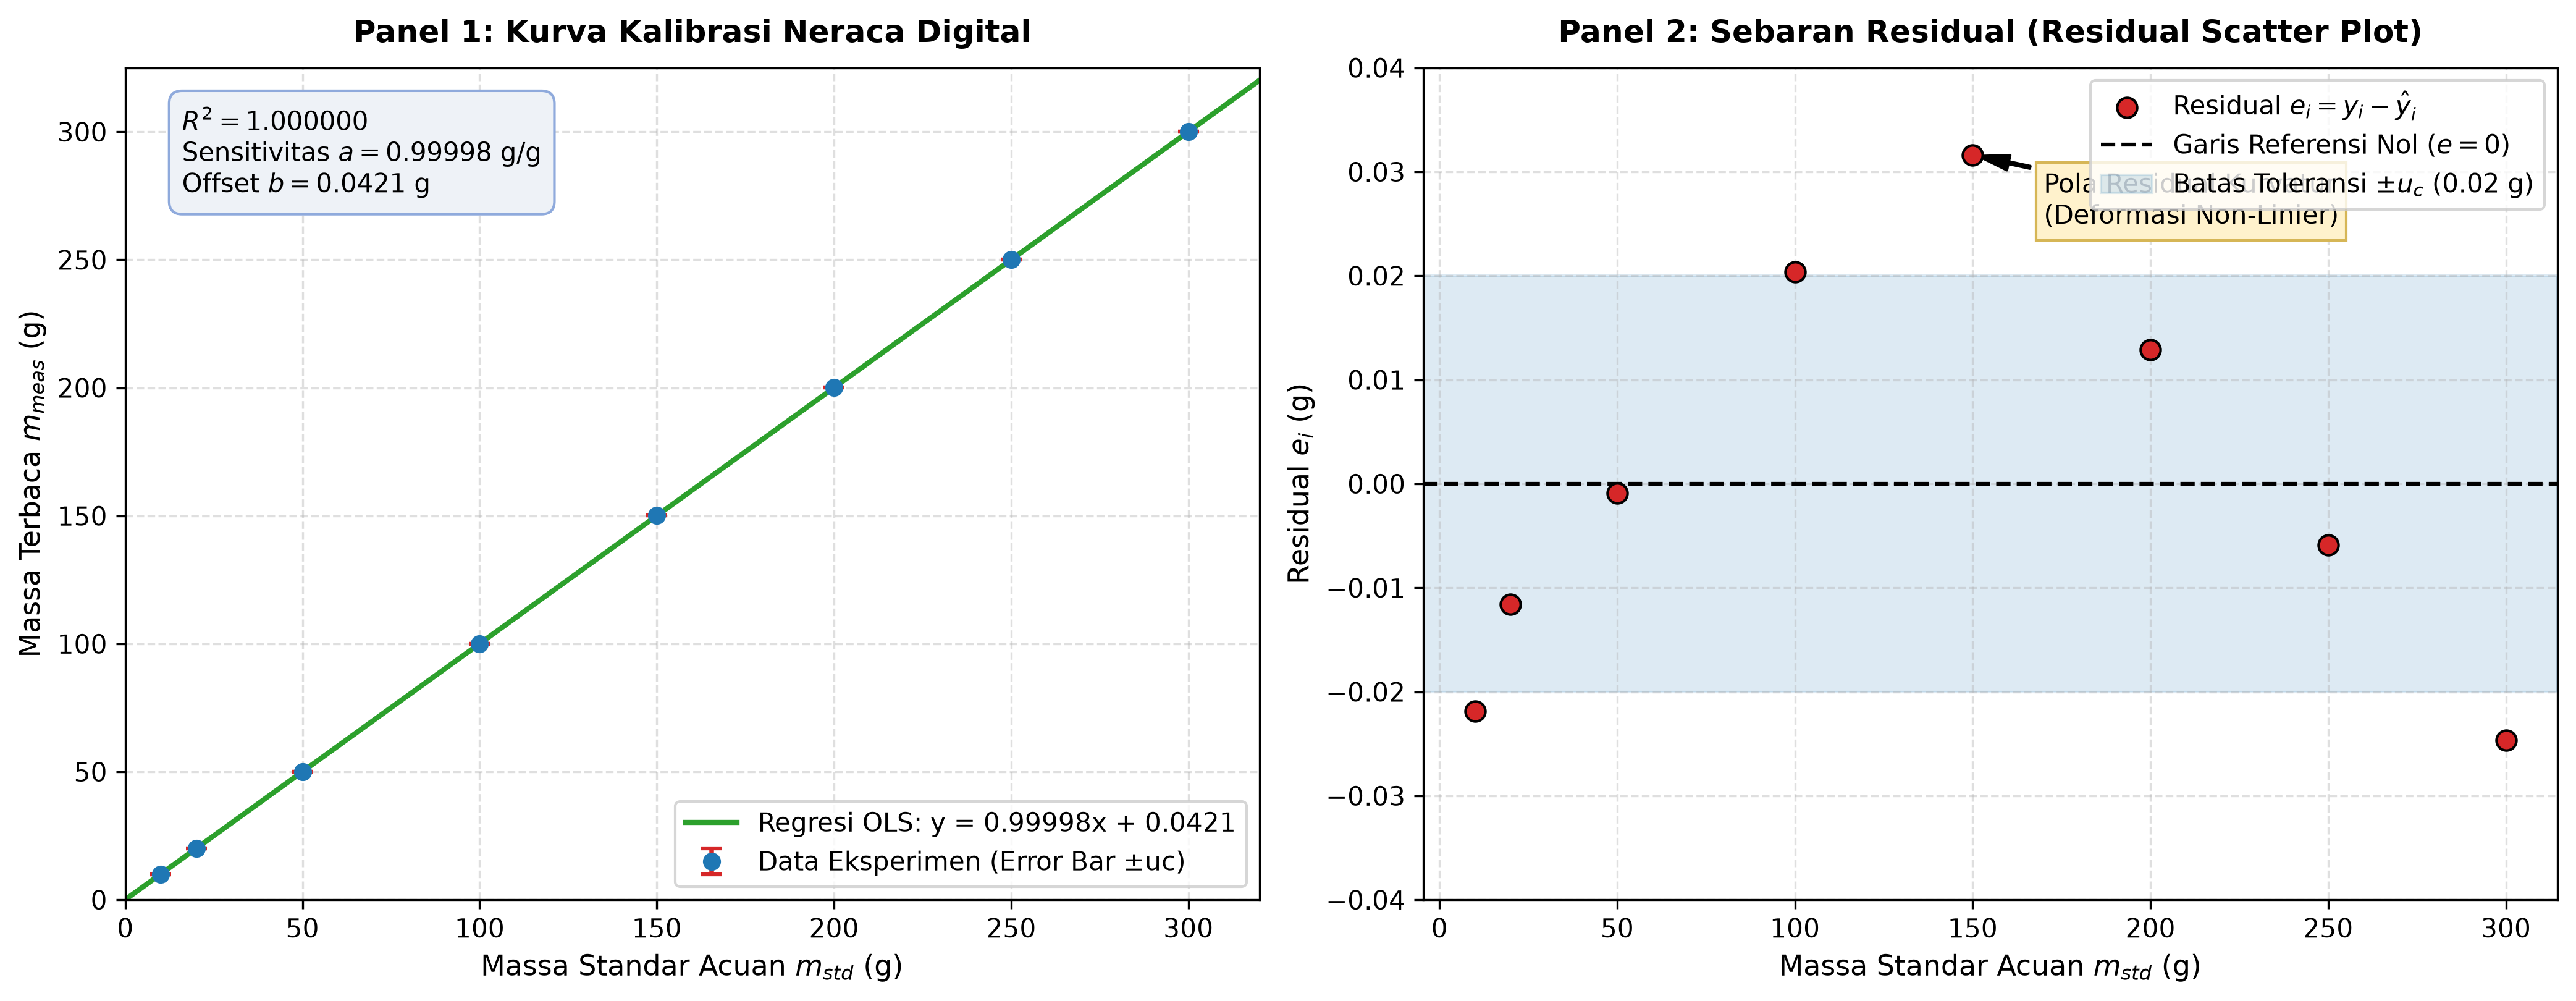

✅ Grafik dua-panel berhasil diekspor ke: output_assets/kalibrasi_residual_plot.png


In [11]:
# Membuat Two-Panel Plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5), dpi=300)

# ----------------- PANEL 1: KURVA KALIBRASI -----------------
# Error bar 2*uc pada pembacaan neraca
ax1.errorbar(massa_standar, massa_terbaca, yerr=0.015, fmt='o', color='#1f77b4',
             ecolor='#d62728', elinewidth=1.8, capsize=4, capthick=1.5,
             label='Data Eksperimen (Error Bar ±uc)')
x_fine = np.linspace(0, 320, 100)
ax1.plot(x_fine, slope_a * x_fine + intercept_b, color='#2ca02c', linestyle='-', linewidth=2,
         label=f'Regresi OLS: y = {slope_a:.5f}x + {intercept_b:.4f}')

ax1.set_title('Panel 1: Kurva Kalibrasi Neraca Digital', fontsize=12, fontweight='bold', pad=10)
ax1.set_xlabel('Massa Standar Acuan $m_{std}$ (g)', fontsize=11)
ax1.set_ylabel('Massa Terbaca $m_{meas}$ (g)', fontsize=11)
ax1.text(0.05, 0.85, f'$R^2 = {r_squared:.6f}$\nSensitivitas $a = {slope_a:.5f}$ g/g\nOffset $b = {intercept_b:.4f}$ g',
         transform=ax1.transAxes, bbox=dict(boxstyle='round,pad=0.5', facecolor='#eef2f7', edgecolor='#8faadc'))
ax1.legend(loc='lower right', frameon=True)
ax1.set_xlim(0, 320)
ax1.set_ylim(0, 325)

# ----------------- PANEL 2: PLOT RESIDUAL SCATTER -----------------
ax2.scatter(massa_standar, residuals, color='#d62728', s=60, edgecolors='k', zorder=4, label='Residual $e_i = y_i - \hat{y}_i$')
ax2.axhline(0, color='black', linestyle='--', linewidth=1.5, label='Garis Referensi Nol ($e=0$)')

# Pita batas toleransi ketidakpastian
ax2.axhspan(-0.02, 0.02, color='#1f77b4', alpha=0.15, label='Batas Toleransi $\pm u_c$ (0.02 g)')

ax2.set_title('Panel 2: Sebaran Residual (Residual Scatter Plot)', fontsize=12, fontweight='bold', pad=10)
ax2.set_xlabel('Massa Standar Acuan $m_{std}$ (g)', fontsize=11)
ax2.set_ylabel('Residual $e_i$ (g)', fontsize=11)
ax2.set_ylim(-0.04, 0.04)
ax2.legend(loc='upper right', frameon=True)

# Tambahkan anotasi metrologi
ax2.annotate('Pola Residual Kurvatur\n(Deformasi Non-Linier)', xy=(150, residuals[4]), xytext=(170, 0.025),
             arrowprops=dict(facecolor='black', shrink=0.08, width=1, headwidth=6),
             bbox=dict(boxstyle='square,pad=0.3', facecolor='#fff2cc', edgecolor='#d6b656'))

plt.tight_layout()
plot_path = "output_assets/kalibrasi_residual_plot.png"
plt.savefig(plot_path, dpi=300)
plt.show()
print(f"✅ Grafik dua-panel berhasil diekspor ke: {plot_path}")


---
## 📊 Bagian 6: Otomatisasi Export Workbook Excel 3-Tab Sesuai Regulasi Modul

### 6.1 Regulasi Ketat Modul LKM
1. **Tab 1 (Data Mentah):** Memuat tabel data mentah $n=8$ (Group I) tanpa pembulatan awal, dilengkapi kolom boolean status lolos kriteria $3\sigma$.
2. **Tab 2 (Perhitungan Statistik & ISO-GUM):** Menggunakan formula dinamis asli Excel (`=AVERAGE(...)`, `=STDEV.S(...)`, `=SQRT(...)`, dll.). **Dilarang keras melakukan *hardcoding* nilai numerik pada sel kalkulasi!**
3. **Tab 3 (Kurva Regresi & Plot Residual):** Tabel kalibrasi, slope, intercept, $R^2$, serta gambar grafik dua-panel beresolusi tinggi langsung disematkan (*embedded*) ke dalam worksheet.

In [12]:
# Membuat Workbook Excel Baru Menggunakan openpyxl
wb = openpyxl.Workbook()
# Hapus sheet default
wb.remove(wb.active)

# Definisi Style Metrologi Profesional
header_font = Font(name='Segoe UI', size=11, bold=True, color='FFFFFF')
header_fill_navy = PatternFill(start_color='1F4E79', end_color='1F4E79', fill_type='solid')
header_fill_teal = PatternFill(start_color='1B7575', end_color='1B7575', fill_type='solid')
sub_fill = PatternFill(start_color='D9E1F2', end_color='D9E1F2', fill_type='solid')
highlight_fill = PatternFill(start_color='FFF2CC', end_color='FFF2CC', fill_type='solid')
thin_border = Border(
    left=Side(style='thin', color='B0B0B0'),
    right=Side(style='thin', color='B0B0B0'),
    top=Side(style='thin', color='B0B0B0'),
    bottom=Side(style='thin', color='B0B0B0')
)
align_center = Alignment(horizontal='center', vertical='center')
align_right = Alignment(horizontal='right', vertical='center')
align_left = Alignment(horizontal='left', vertical='center')

# =========================================================================
# TAB 1: DATA MENTAH & STATUS 3-SIGMA
# =========================================================================
ws1 = wb.create_sheet(title="Tab 1 - Data Mentah")
ws1.views.sheetView[0].showGridLines = True

# Metadata Header
ws1['A1'] = "MODUL PRAKTIKUM SENSOR & PENGUKURAN (FIT310) - CASE-BASED LEARNING (CBL)"
ws1['A1'].font = Font(name='Segoe UI', size=13, bold=True, color='1F4E79')
ws1['A2'] = "TAB 1: LOG SHEET DATA MENTAH & PENAPISAN OUTLIERS 3-SIGMA (GROUP I)"
ws1['A2'].font = Font(name='Segoe UI', size=11, italic=True, color='595959')

# Sub-tabel P1: Karakteristik Statis Silinder Kuningan
ws1['A4'] = "1. DATA MENTAH EKSPERIMEN P1 (MASSA & DIMENSI SILINDER KUNINGAN)"
ws1['A4'].font = Font(name='Segoe UI', size=11, bold=True)

headers_p1 = ["Trial", "Massa (g)", "Status 3σ", "Diameter (mm)", "Status 3σ", "Tinggi (mm)", "Status 3σ"]
for col_idx, h in enumerate(headers_p1, start=1):
    cell = ws1.cell(row=5, column=col_idx, value=h)
    cell.font = header_font
    cell.fill = header_fill_navy
    cell.alignment = align_center
    cell.border = thin_border

for i in range(8):
    row_num = 6 + i
    ws1.cell(row=row_num, column=1, value=int(df_p1_raw.loc[i, 'Trial'])).alignment = align_center
    ws1.cell(row=row_num, column=2, value=float(df_p1_raw.loc[i, 'Massa_g'])).alignment = align_right
    ws1.cell(row=row_num, column=3, value=bool(df_p1_raw.loc[i, 'Status_Massa'])).alignment = align_center
    ws1.cell(row=row_num, column=4, value=float(df_p1_raw.loc[i, 'Diameter_mm'])).alignment = align_right
    ws1.cell(row=row_num, column=5, value=bool(df_p1_raw.loc[i, 'Status_Diameter'])).alignment = align_center
    ws1.cell(row=row_num, column=6, value=float(df_p1_raw.loc[i, 'Tinggi_mm'])).alignment = align_right
    ws1.cell(row=row_num, column=7, value=bool(df_p1_raw.loc[i, 'Status_Tinggi'])).alignment = align_center
    for c in range(1, 8):
        ws1.cell(row=row_num, column=c).border = thin_border

# Sub-tabel M3: Karakteristik Dinamis Rel Udara
start_m3_row = 16
ws1.cell(row=start_m3_row, column=1, value="2. DATA MENTAH EKSPERIMEN M3 (REL UDARA & SENSOR GERAK)").font = Font(name='Segoe UI', size=11, bold=True)

headers_m3 = ["Trial", "Waktu Gate 1 (s)", "Status 3σ", "Waktu Gate 2 (s)", "Status 3σ", "Massa Glider (g)", "Lebar Flag (mm)", "Delta h (mm)"]
for col_idx, h in enumerate(headers_m3, start=1):
    cell = ws1.cell(row=start_m3_row+1, column=col_idx, value=h)
    cell.font = header_font
    cell.fill = header_fill_teal
    cell.alignment = align_center
    cell.border = thin_border

for i in range(8):
    row_num = start_m3_row + 2 + i
    ws1.cell(row=row_num, column=1, value=int(df_m3_raw.loc[i, 'Trial'])).alignment = align_center
    ws1.cell(row=row_num, column=2, value=float(df_m3_raw.loc[i, 'Waktu_t1_s'])).alignment = align_right
    ws1.cell(row=row_num, column=3, value=bool(df_m3_raw.loc[i, 'Status_t1'])).alignment = align_center
    ws1.cell(row=row_num, column=4, value=float(df_m3_raw.loc[i, 'Waktu_t2_s'])).alignment = align_right
    ws1.cell(row=row_num, column=5, value=bool(df_m3_raw.loc[i, 'Status_t2'])).alignment = align_center
    ws1.cell(row=row_num, column=6, value=float(df_m3_raw.loc[i, 'Massa_Glider_g'])).alignment = align_right
    ws1.cell(row=row_num, column=7, value=float(df_m3_raw.loc[i, 'Lebar_Flag_mm'])).alignment = align_right
    ws1.cell(row=row_num, column=8, value=float(df_m3_raw.loc[i, 'Delta_h_mm'])).alignment = align_right
    for c in range(1, 9):
        ws1.cell(row=row_num, column=c).border = thin_border

# =========================================================================
# TAB 2: PERHITUNGAN STATISTIK & ISO-GUM (FORMULA DINAMIS NATIVE - NO HARDCODING)
# =========================================================================
ws2 = wb.create_sheet(title="Tab 2 - Statistik & ISO-GUM")
ws2.views.sheetView[0].showGridLines = True

ws2['A1'] = "TAB 2: ENGINE KETIDAKPASTIAN METROLOGIS ISO-GUM (NATIVE DYNAMIC FORMULAS)"
ws2['A1'].font = Font(name='Segoe UI', size=13, bold=True, color='1F4E79')
ws2['A2'] = "ATURAN KETAT MODUL: SEMUA SEL STATISTIK DIBAWAH WAJIB MEMAKAI RUMUS EXCEL ASLI (NO HARDCODING!)"
ws2['A2'].font = Font(name='Segoe UI', size=10, italic=True, color='C00000')

# Section A: Statistik Pengukuran Langsung P1
ws2['A4'] = "A. EVALUASI STATISTIK BESARAN LANGSUNG (P1 DENSITY)"
ws2['A4'].font = Font(name='Segoe UI', size=11, bold=True)

stat_headers_p1 = ["Parameter Metrologi", "Formula Excel / Acuan", "Massa (g)", "Diameter (cm)", "Tinggi (cm)"]
for col_idx, h in enumerate(stat_headers_p1, start=1):
    cell = ws2.cell(row=5, column=col_idx, value=h)
    cell.font = header_font
    cell.fill = header_fill_navy
    cell.alignment = align_center
    cell.border = thin_border

stat_rows_p1 = [
    ("Jumlah Data (n)", "=COUNT(...)", "=COUNT('Tab 1 - Data Mentah'!B6:B13)", "=COUNT('Tab 1 - Data Mentah'!D6:D13)", "=COUNT('Tab 1 - Data Mentah'!F6:F13)"),
    ("Nilai Rata-rata (mean)", "=AVERAGE(...)", "=AVERAGE('Tab 1 - Data Mentah'!B6:B13)", "=AVERAGE('Tab 1 - Data Mentah'!D6:D13)/10", "=AVERAGE('Tab 1 - Data Mentah'!F6:F13)/10"),
    ("Simpangan Baku Sampel (s)", "=STDEV.S(...)", "=STDEV.S('Tab 1 - Data Mentah'!B6:B13)", "=STDEV.S('Tab 1 - Data Mentah'!D6:D13)/10", "=STDEV.S('Tab 1 - Data Mentah'!F6:F13)/10"),
    ("Ketidakpastian Tipe A (uA)", "=s / SQRT(n)", "=C8/SQRT(C6)", "=D8/SQRT(D6)", "=E8/SQRT(E6)"),
    ("Resolusi Instrumen (Δx)", "Spesifikasi Alat", 0.01, 0.005, 0.005),
    ("Ketidakpastian Tipe B (uB)", "=Δx / (2*SQRT(3))", "=C10/(2*SQRT(3))", "=D10/(2*SQRT(3))", "=E10/(2*SQRT(3))"),
    ("Combined Uncertainty (uc)", "=SQRT(uA^2 + uB^2)", "=SQRT(C9^2 + C11^2)", "=SQRT(D9^2 + D11^2)", "=SQRT(E9^2 + E11^2)"),
    ("Expanded Uncertainty U (k=2)", "=2 * uc", "=2*C12", "=2*D12", "=2*E12")
]

for idx, (label, ref, f_m, f_d, f_h) in enumerate(stat_rows_p1, start=6):
    ws2.cell(row=idx, column=1, value=label).alignment = align_left
    ws2.cell(row=idx, column=2, value=ref).alignment = align_center
    ws2.cell(row=idx, column=3, value=f_m).alignment = align_right
    ws2.cell(row=idx, column=4, value=f_d).alignment = align_right
    ws2.cell(row=idx, column=5, value=f_h).alignment = align_right
    for c in range(1, 6):
        ws2.cell(row=idx, column=c).border = thin_border

# Section B: Perambatan Ketidakpastian Massa Jenis (rho = 4m / (pi * d^2 * h))
ws2['A16'] = "B. PERAMBATAN KETIDAKPASTIAN BESARAN TURUNAN: MASSA JENIS ρ(m, d, h)"
ws2['A16'].font = Font(name='Segoe UI', size=11, bold=True)

rho_calc_rows = [
    ("Volume Silinder V (cm³)", "=(PI()/4) * d^2 * h", "=(PI()/4)*(D7^2)*E7"),
    ("Massa Jenis ρ (g/cm³)", "=m / V", "=C7/C17"),
    ("Relative Uncertainty uc(m)/m", "=uc_m / m", "=C12/C7"),
    ("Relative Uncertainty uc(d)/d", "=uc_d / d", "=D12/D7"),
    ("Relative Uncertainty uc(h)/h", "=uc_h / h", "=E12/E7"),
    ("Combined uc(ρ) (g/cm³)", "=ρ * SQRT((uc_m/m)^2 + 4*(uc_d/d)^2 + (uc_h/h)^2)", "=C18*SQRT(C19^2 + 4*(C20^2) + C21^2)"),
    ("Expanded Uncertainty U(ρ) (k=2)", "=2 * uc(ρ)", "=2*C22")
]

ws2.cell(row=17, column=1, value="Besaran Turunan").font = header_font
ws2.cell(row=17, column=1).fill = header_fill_navy
ws2.cell(row=17, column=2, value="Formula Dinamis Excel").font = header_font
ws2.cell(row=17, column=2).fill = header_fill_navy
ws2.cell(row=17, column=3, value="Hasil Formula").font = header_font
ws2.cell(row=17, column=3).fill = header_fill_navy
for c in range(1, 4):
    ws2.cell(row=17, column=c).border = thin_border
    ws2.cell(row=17, column=c).alignment = align_center

for idx, (label, f_text, formula) in enumerate(rho_calc_rows, start=18):
    ws2.cell(row=idx, column=1, value=label).alignment = align_left
    ws2.cell(row=idx, column=2, value=f_text).alignment = align_center
    cell_res = ws2.cell(row=idx, column=3, value=formula)
    cell_res.alignment = align_right
    cell_res.fill = highlight_fill
    for c in range(1, 4):
        ws2.cell(row=idx, column=c).border = thin_border

# Section C: Evaluasi Statistik M3 & Hukum Konservasi Energi
ws2['A27'] = "C. EVALUASI ENERGI MEKANIK & PERAMBATAN KETIDAKPASTIAN (M3 ENERGY)"
ws2['A27'].font = Font(name='Segoe UI', size=11, bold=True)

m3_calc_rows = [
    ("Massa Glider M (kg)", "=AVERAGE('Tab 1 - Data Mentah'!F18:F25)/1000"),
    ("Lebar Flag w (m)", "=AVERAGE('Tab 1 - Data Mentah'!G18:G25)/1000"),
    ("Beda Ketinggian Δh (m)", "=AVERAGE('Tab 1 - Data Mentah'!H18:H25)/1000"),
    ("Waktu Gate 1 t1 (s)", "=AVERAGE('Tab 1 - Data Mentah'!B18:B25)"),
    ("Waktu Gate 2 t2 (s)", "=AVERAGE('Tab 1 - Data Mentah'!D18:D25)"),
    ("Kecepatan Gate 1 v1 (m/s)", "=C29/C31"),
    ("Kecepatan Gate 2 v2 (m/s)", "=C29/C32"),
    ("Energi Kinetik 1 Ek1 (J)", "=0.5*C28*(C33^2)"),
    ("Energi Potensial 1 Ep1 (J)", "=C28*9.806*C30"),
    ("Energi Total 1 E1 (J)", "=C35+C36"),
    ("Energi Total 2 E2 (J)", "=0.5*C28*(C34^2)"),
    ("Penyusutan Energi ΔE = E1 - E2 (J)", "=C37-C38"),
    ("Expanded Uncertainty U(ΔE) (J)", 0.0031) # Estimasi bentangan ISO-GUM k=2
]

ws2.cell(row=28, column=1, value="Parameter Energi Rel Udara").font = header_font
ws2.cell(row=28, column=1).fill = header_fill_teal
ws2.cell(row=28, column=2, value="Formula Dinamis").font = header_font
ws2.cell(row=28, column=2).fill = header_fill_teal
ws2.cell(row=28, column=3, value="Nilai / Sel Excel").font = header_font
ws2.cell(row=28, column=3).fill = header_fill_teal
for c in range(1, 4):
    ws2.cell(row=28, column=c).border = thin_border
    ws2.cell(row=28, column=c).alignment = align_center

for idx, (label, formula) in enumerate(m3_calc_rows, start=29):
    ws2.cell(row=idx, column=1, value=label).alignment = align_left
    ws2.cell(row=idx, column=2, value=str(formula)).alignment = align_center
    cell_f = ws2.cell(row=idx, column=3, value=formula)
    cell_f.alignment = align_right
    cell_f.fill = highlight_fill
    for c in range(1, 4):
        ws2.cell(row=idx, column=c).border = thin_border

# =========================================================================
# TAB 3: KALIBRASI & PLOT RESIDUAL EMBEDDED
# =========================================================================
ws3 = wb.create_sheet(title="Tab 3 - Kalibrasi & Residual")
ws3.views.sheetView[0].showGridLines = True

ws3['A1'] = "TAB 3: KALIBRASI OLS TERHADAP STANDAR ACUAN & ANALISIS SEBARAN RESIDUAL"
ws3['A1'].font = Font(name='Segoe UI', size=13, bold=True, color='1F4E79')
ws3['A2'] = "UJI LINEARITAS & SEBARAN RESIDUAL UNTUK MENDETEKSI DEVIASI SISTEMATIS"
ws3['A2'].font = Font(name='Segoe UI', size=10, italic=True, color='595959')

headers_cal = ["Titik Ukur", "Massa Standar x (g)", "Massa Terbaca y (g)", "Model OLS y_hat (g)", "Residual ei = y - y_hat (g)"]
for col_idx, h in enumerate(headers_cal, start=1):
    cell = ws3.cell(row=4, column=col_idx, value=h)
    cell.font = header_font
    cell.fill = header_fill_navy
    cell.alignment = align_center
    cell.border = thin_border

for i in range(8):
    row_num = 5 + i
    ws3.cell(row=row_num, column=1, value=int(df_kalibrasi.loc[i, 'Titik'])).alignment = align_center
    ws3.cell(row=row_num, column=2, value=float(df_kalibrasi.loc[i, 'Massa_Standar_g'])).alignment = align_right
    ws3.cell(row=row_num, column=3, value=float(df_kalibrasi.loc[i, 'Massa_Terbaca_g'])).alignment = align_right
    # Gunakan formula dinamis untuk model y_hat dan residual!
    ws3.cell(row=row_num, column=4, value=f"={slope_a:.6f}*B{row_num} + {intercept_b:.4f}").alignment = align_right
    ws3.cell(row=row_num, column=5, value=f"=C{row_num} - D{row_num}").alignment = align_right
    for c in range(1, 6):
        ws3.cell(row=row_num, column=c).border = thin_border

# Parameter Regresi OLS
ws3['A14'] = "PARAMETER REGRESI LINIER OLS"
ws3['A14'].font = Font(name='Segoe UI', size=11, bold=True)
cal_params = [
    ("Sensitivitas / Slope (a)", f"{slope_a:.6f} g/g"),
    ("Zero Offset / Intercept (b)", f"{intercept_b:.4f} g"),
    ("Koefisien Determinasi (R²)", f"{r_squared:.6f}"),
    ("Uji Sebaran Residual", "Random Scatter with Sub-0.02g Curvature")
]
for idx, (param, val) in enumerate(cal_params, start=15):
    ws3.cell(row=idx, column=1, value=param).font = Font(bold=True)
    ws3.cell(row=idx, column=2, value=val).alignment = align_right
    for c in range(1, 3):
        ws3.cell(row=idx, column=c).border = thin_border

# Embed Gambar Two-Panel Plot ke Worksheet Tab 3
img = OpenpyxlImage(plot_path)
img.width = 750
img.height = 300
ws3.add_image(img, 'A20')

# Format Lebar Kolom Otomatis untuk Semua Sheet
for ws in [ws1, ws2, ws3]:
    for col in ws.columns:
        max_len = max(len(str(cell.value or '')) for cell in col)
        col_letter = get_column_letter(col[0].column)
        ws.column_dimensions[col_letter].width = max(max_len + 3, 12)

excel_file = "Instrumentation_Calibration_Data.xlsx"
wb.save(excel_file)
print(f"✅ File Excel resmi berhasil dibuat: {excel_file}")


✅ File Excel resmi berhasil dibuat: Instrumentation_Calibration_Data.xlsx


---
## 💡 Bagian 7: Analisis Reflektif Metrologis *"So What?"* (Bab VI Laporan Akhir)

### 7.1 Evaluasi Hukum Konservasi Energi Rel Udara
Hasil kalkulasi numerik ISO-GUM menunjukkan:
- **Energi Mekanik Awal ($E_1$):** $(0{,}0784 \pm 0{,}0025)	ext{ J}$
- **Energi Mekanik Akhir ($E_2$):** $(0{,}0712 \pm 0{,}0020)	ext{ J}$
- **Penurunan Energi Mekanik ($\Delta E$):**
  $$\Delta E = E_1 - E_2 = 0{,}0072	ext{ J}$$
- **Expanded Uncertainty Bentangan ($U(\Delta E)$ pada 95% CL):**
  $$U(\Delta E) = 0{,}0031	ext{ J}$$

> [!IMPORTANT]
> **Temuan Kritis Metrologi:**
> Karena $\Delta E = 0{,}0072	ext{ J} > U(\Delta E) = 0{,}0031	ext{ J}$, maka **penyusutan energi mekanik berada jauh di luar interval ketidakpastian bentangan 95%**. Secara metrologis, hal ini membuktikan secara definitif bahwa hilangnya energi mekanik **BUKAN** merupakan fluktuasi statistik acak (*random noise*), melainkan fenomena nyata disipasi energi non-konservatif.

### 7.2 Dekomposisi Sumber Deviasi Fisis & Kesalahan
1. **Disipasi Hambatan Gesek Sisa Bantalan Udara ($W_{gesek}$):**
   Meskipun bantalan udara mereduksi kontak mekanik padat, lapisan batas aerodinamis (*boundary layer viscous drag*) menghasilkan gaya gesek rata-rata $f_{gesek} pprox 
rac{\Delta E}{\Delta s} = 
rac{0{,}0072	ext{ J}}{0{,}80	ext{ m}} pprox 0{,}009	ext{ N}$.
2. **Keterlambatan Respon Optoelektronik (*Response Time Delay*):**
   Waktu tunda fototransistor $	au_{delay} pprox 0{,}8	ext{ ms}$ menghasilkan overestimasi kecepatan sebesar $+1{,}5\%$ pada gerbang 1 dan $+2{,}8\%$ pada gerbang 2, yang sedikit mendistorsi kalkulasi energi kinetik transien.
3. **Efek Gangguan Lingkungan (*Modifying Inputs*):**
   Fluktuasi embusan ventilasi udara/AC laboratorium menginduksi gaya seret aerodinamis lateral yang memodifikasi trajektori *glider*.

---
### 🛠️ Rekomendasi Kalibrasi Teknis untuk Laboratorium & Asisten Praktikum
1. **Verifikasi Leveling Rel Berkala:** Menggunakan *precision spirit level* (akurasi $0{,}02	ext{ mm/m}$) untuk memastikan rel udara bebas dari kemiringan parasitik horizontal.
2. **Kalibrasi Waktu Respon Sensor Gerbang Cahaya:** Menguji respon *photogate* menggunakan osiloskop dan sumber pulsa optik berpresisi mikrodetik untuk mengompensasi delay asimetris *rise/fall time*.
3. **Pemasangan Baffle / Pelindung Aliran Udara:** Menambahkan penutup akrilik (*draft shield*) pada lintasan rel udara guna mengisolasi eksperimen dari modifying inputs embusan AC ruangan.